# 01 — Analyse de la qualité des données & statistiques descriptives

**SciPulse — Projet #4** · Yahya Qabil

Ce notebook couvre le premier livrable d'analyse demandé par le brief :

1. **Analyse de la qualité** des données brutes (couche Bronze) : valeurs manquantes, types, doublons, anomalies ;
2. **Statistiques descriptives** avec visualisations sur les données nettoyées (couche Silver) ;
3. **Procédure de nettoyage** documentée, guidée par les validations Great Expectations ;
4. **Couverture des jointures** entre les trois sources.

> **Prérequis** : la stack Docker tourne (`docker compose up -d`) et les DAGs Bronze/Silver ont été exécutés.
> Le notebook lit MinIO (`localhost:9000`) via le package `scipulse` du dépôt.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipulse.common.storage import list_keys, read_jsonl
from scipulse.common.parquet import read_parquet
from scipulse.config import buckets

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4)
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)

def load_bronze(bucket, max_files=1, prefix="", latest=False):
    # Charge les premiers fichiers JSON Lines d'un bucket Bronze (échantillon)
    keys = sorted(list_keys(bucket, prefix), reverse=latest)[:max_files]
    return pd.DataFrame([r for k in keys for r in read_jsonl(bucket, k)]), keys

## 1. Couche Bronze — analyse de la qualité

La couche Bronze contient les données **telles qu'ingérées**, sans transformation. On en analyse un échantillon
(le premier fichier de chaque source) pour identifier les problèmes que le nettoyage devra traiter.

### 1.1 ArXiv (dump Kaggle)

In [2]:
arxiv_raw, keys = load_bronze(buckets.ARXIV_RAW, max_files=1)
print(f"Fichier : {keys}  —  {len(arxiv_raw):,} lignes, {arxiv_raw.shape[1]} colonnes")
arxiv_raw.head(3)

Fichier : ['ingest_date=2026-10-18/part-00000.jsonl']  —  50,000 lignes, 14 colonnes


,id,submitter,authors,title,comments,journal-ref,doi,report-no,categories,license,abstract,versions,update_date,authors_parsed
0,0704.0646,Max Tegmark,Max Tegmark (MIT),The Mathematical Universe,"Replaced to match accepted Found. Phys. version, 31 pages, 5 figs;\n more d...","Found.Phys.38:101-150,2008",10.1007/s10701-007-9186-9,None,gr-qc astro-ph hep-th,None,I explore physics implications of the External Reality Hypothesis (ERH) th...,"[{'version': 'v1', 'created': 'Thu, 5 Apr 2007 14:47:46 GMT'}, {'version': '...",2008-11-26,"[[Tegmark, Max, , MIT]]"
1,0704.0834,Anatoly Rodionov,"Anatoly Rodionov, Sergey Volkov",P-adic arithmetic coding,29 pages,None,None,None,cs.DS,None,A new incremental algorithm for data compression is presented. For a seque...,"[{'version': 'v1', 'created': 'Fri, 6 Apr 2007 02:30:42 GMT'}]",2007-05-23,"[[Rodionov, Anatoly, ], [Volkov, Sergey, ]]"
2,0704.1147,Giulio Ruffini,Giulio Ruffini,"Information, complexity, brains and reality (Kolmogorov Manifesto)","This is a live essay, kind of a mental log book on a series of topics\n und...",None,None,Starlab TN00054,physics.gen-ph physics.bio-ph,None,I discuss several aspects of information theory and its relationship to\np...,"[{'version': 'v1', 'created': 'Mon, 9 Apr 2007 20:17:39 GMT'}]",2007-05-23,"[[Ruffini, Giulio, ]]"


In [3]:
def quality_report(df):
    # Taux de valeurs manquantes (None / NaN / chaîne vide) et type Python dominant par colonne
    rep = pd.DataFrame({
        "manquants_%": (df.isna() | df.astype(str).eq("")).mean().mul(100).round(2),
        "type_dominant": df.apply(lambda s: s.dropna().map(lambda v: type(v).__name__).mode().iat[0] if s.notna().any() else "—"),
        "valeurs_distinctes": df.apply(lambda s: s.astype(str).nunique()),
    })
    return rep.sort_values("manquants_%", ascending=False)

quality_report(arxiv_raw)

,manquants_%,type_dominant,valeurs_distinctes
report-no,99.16,str,416
journal-ref,87.87,str,5839
doi,81.72,str,9135
comments,42.20,str,21766
license,0.08,str,10
submitter,0.00,str,38578
authors,0.00,str,48884
title,0.00,str,49999
id,0.00,str,50000
categories,0.00,str,7271


In [4]:
n = len(arxiv_raw)
dups = arxiv_raw["id"].duplicated().sum()
versions = arxiv_raw["versions"].map(len)
abstract_len = arxiv_raw["abstract"].fillna("").str.strip().str.len()
title_multiline = arxiv_raw["title"].fillna("").str.contains("\n").mean()

anomalies = pd.Series({
    "identifiants dupliqués": dups,
    "articles à plusieurs versions": int((versions > 1).sum()),
    "résumés < 20 caractères": int((abstract_len < 20).sum()),
    "titres sur plusieurs lignes (%)": round(100 * title_multiline, 1),
    "DOI renseigné (%)": round(100 * arxiv_raw["doi"].notna().mean(), 1),
    "catégories multiples (%)": round(100 * arxiv_raw["categories"].str.contains(" ").mean(), 1),
}, name="ArXiv Bronze")
anomalies.to_frame()

,ArXiv Bronze
identifiants dupliqués,0.0
articles à plusieurs versions,23072.0
résumés < 20 caractères,1.0
titres sur plusieurs lignes (%),49.4
DOI renseigné (%),18.3
catégories multiples (%),64.5


In [5]:
# Le cas qui fait échouer la règle GE « résumé ≥ 20 caractères »
arxiv_raw.loc[abstract_len < 20, ["id", "title", "abstract"]]

,id,title,abstract
362,1110.2832,Can apparent superluminal neutrino speeds be explained as a quantum weak\n ...,Probably not.\n


**Constats ArXiv :**

- Le DOI est **rarement renseigné** : il ne peut pas servir de clé de jointure principale → on utilise l'**identifiant ArXiv**.
- Les **dates** ne sont pas dans un champ dédié : la date de soumission est dans `versions[0].created` au format RFC 2822
  (`Mon, 2 Apr 2007 19:18:42 GMT`) → parsing nécessaire.
- Les **titres et résumés** contiennent des retours à la ligne et des espaces multiples → normalisation.
- `categories` est une **chaîne multi-valuée** (`"cs.LG stat.ML"`) → découpage en liste + extraction de la catégorie principale.
- Un résumé de 13 caractères (*« Probably not. »*) : anomalie statistique mais **donnée légitime** (voir §3).

### 1.2 Hacker News (API Firebase + backfill Algolia)

In [6]:
hn_raw, keys = load_bronze(buckets.HN_RAW, max_files=50)
print(f"{len(keys)} fichiers, {len(hn_raw):,} items")
hn_raw["_source"].value_counts().to_frame("items")

50 fichiers, 49,182 items


,items
_source,
algolia,48208
firebase,974


In [7]:
# Les deux API n'ont pas le même schéma : colonnes présentes selon la source
schema = (hn_raw.groupby("_source").apply(lambda g: g.notna().mean()).T.mul(100).round(0))
schema.loc[["id", "objectID", "score", "points", "descendants", "num_comments", "time", "created_at_i", "url"]
           if "objectID" in schema.index else schema.index]

_source,algolia,firebase
id,0.0,100.0
objectID,100.0,0.0
score,0.0,100.0
points,100.0,0.0
descendants,0.0,100.0
num_comments,100.0,0.0
time,0.0,100.0
created_at_i,100.0,0.0
url,100.0,97.0


In [8]:
hn_id = pd.to_numeric(hn_raw.get("id"), errors="coerce").fillna(pd.to_numeric(hn_raw.get("objectID"), errors="coerce"))
url = hn_raw["url"].fillna("")
hn_anom = pd.Series({
    "items en double (même id, poll + backfill)": int(hn_id.duplicated().sum()),
    "items supprimés (deleted)": int(hn_raw.get("deleted", pd.Series(dtype=bool)).fillna(False).sum()),
    "items sans URL (%)": round(100 * url.eq("").mean(), 1),
    "URL pointant vers arxiv.org (%)": round(100 * url.str.contains("arxiv.org").mean(), 1),
}, name="HN Bronze")
hn_anom.to_frame()

,HN Bronze
"items en double (même id, poll + backfill)",24110.0
items supprimés (deleted),0.0
items sans URL (%),0.1
URL pointant vers arxiv.org (%),98.0


**Constats Hacker News :**

- **Deux schémas différents** : Firebase (`id`, `score`, `descendants`, `time`) et Algolia (`objectID`, `points`,
  `num_comments`, `created_at_i`) → harmonisation dans un schéma unique.
- **Doublons** : un même post peut être vu par le backfill et par le polling, ou plusieurs fois par le polling → déduplication
  sur `hn_id` en gardant le score le plus récent.
- Items **supprimés** / `dead` et items sans URL → filtrés.
- L'identifiant ArXiv n'existe pas en tant que champ : il est **extrait de l'URL** (`abs/`, `pdf/`, `html/`, avec version).

### 1.3 Citations (OpenAlex)

In [9]:
cit_raw, keys = load_bronze(buckets.CITATIONS_RAW, max_files=20, latest=True)
print(f"{len(keys)} fichiers, {len(cit_raw):,} works OpenAlex")
doi_is_arxiv = cit_raw["doi"].fillna("").str.contains("10.48550/arxiv", case=False)
pd.Series({
    "DOI principal = DOI arXiv (%)": round(100 * doi_is_arxiv.mean(), 1),
    "id ArXiv retrouvé via locations (%)": round(100 * cit_raw.get("_arxiv_id", pd.Series(dtype=object)).notna().mean(), 1),
    "articles avec 0 citation (%)": round(100 * cit_raw["cited_by_count"].eq(0).mean(), 1),
}).to_frame("OpenAlex Bronze")

20 fichiers, 401 works OpenAlex


,OpenAlex Bronze
DOI principal = DOI arXiv (%),40.4
id ArXiv retrouvé via locations (%),100.0
articles avec 0 citation (%),61.1


**Constat clé OpenAlex :** le champ `doi` pointe le plus souvent vers la **version publiée** de l'article
(ex. `10.65215/…` pour *Attention Is All You Need*), **pas** vers le DOI arXiv `10.48550/arxiv.<id>`.
Une jointure naïve sur le DOI perdrait la quasi-totalité des citations. La solution retenue retrouve l'identifiant
ArXiv dans le champ `locations` (`arxiv.org/abs/…`) et l'enregistre dans `_arxiv_id` à l'ingestion.

## 2. Couche Silver — statistiques descriptives

Données nettoyées, validées par Great Expectations et stockées en Parquet (une table par source).

In [10]:
arxiv = read_parquet(buckets.ARXIV_CLEAN, columns=["arxiv_id", "primary_category", "category_group", "submitted_date",
                                                   "n_versions", "abstract", "year", "doi"])
arxiv["year"] = arxiv["year"].astype(int)          # colonne de partition relue en « category »
arxiv["abstract_len"] = arxiv["abstract"].str.len()
hn = read_parquet(buckets.HN_CLEAN)
hn["year"] = hn["year"].astype(int)
cit = read_parquet(buckets.CITATIONS_CLEAN, columns=["arxiv_id", "cited_by_count", "publication_year"])

pd.DataFrame({
    "lignes": [len(arxiv), len(hn), len(cit)],
    "clé unique": [arxiv.arxiv_id.is_unique, hn.hn_id.is_unique, cit.arxiv_id.is_unique],
}, index=["ArXiv", "Hacker News", "Citations"])

,lignes,clé unique
ArXiv,218851,True
Hacker News,25511,True
Citations,22472,True


In [11]:
arxiv[["n_versions", "abstract_len", "year"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
n_versions,218851.0,1.7,1.0,1.0,1.0,1.0,2.0,54.0
abstract_len,218851.0,1255.8,340.5,13.0,1027.0,1257.0,1494.0,4080.0
year,218851.0,2024.1,1.6,1991.0,2024.0,2024.0,2025.0,2026.0


### 2.1 Répartition par catégorie

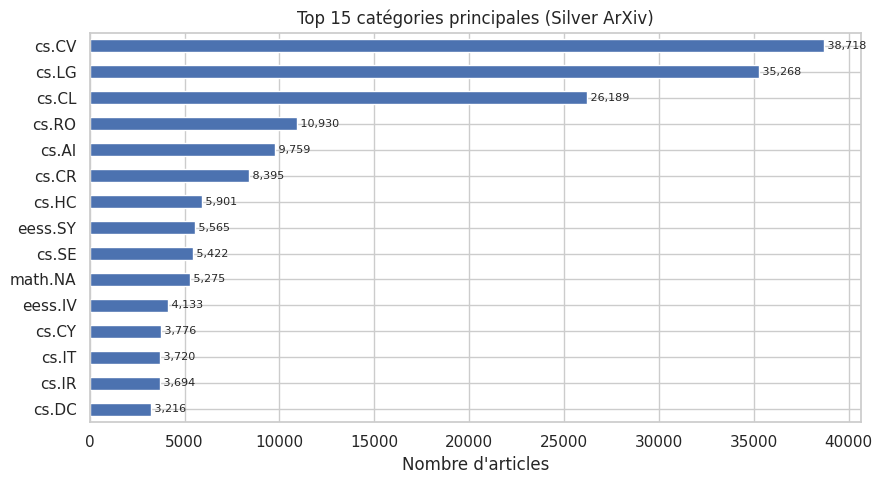

Les 5 premières catégories représentent 55% du corpus.


In [12]:
top = arxiv["primary_category"].value_counts().head(15)
ax = top.sort_values().plot.barh(color=sns.color_palette()[0], figsize=(9, 5))
ax.set(title="Top 15 catégories principales (Silver ArXiv)", xlabel="Nombre d'articles", ylabel="")
for i, v in enumerate(top.sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "01_categories.png", dpi=120); plt.show()
print(f"Les 5 premières catégories représentent {top.head(5).sum() / len(arxiv):.0%} du corpus.")

### 2.2 Évolution temporelle des publications

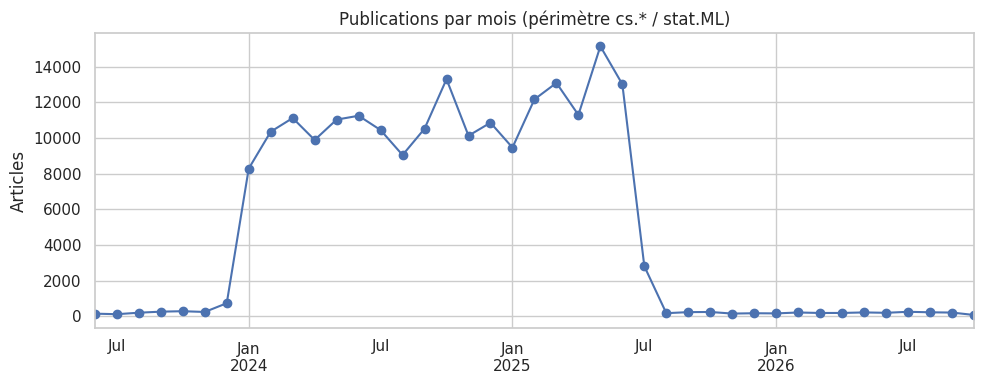

In [13]:
monthly = arxiv.set_index("submitted_date").resample("MS").size()
monthly = monthly[monthly.index >= "2023-06-01"]
ax = monthly.plot(marker="o", figsize=(10, 4))
ax.set(title="Publications par mois (périmètre cs.* / stat.ML)", xlabel="", ylabel="Articles")
plt.tight_layout(); plt.savefig(FIG / "01_publications_mensuelles.png", dpi=120); plt.show()

> **Lecture** : la chute brutale en fin de période n'est pas une baisse de la recherche. C'est l'effet du **plafond
> d'échantillonnage** (`ARXIV_MAX_RECORDS`) : le dump est trié chronologiquement et l'ingestion s'arrête une fois le plafond
> atteint (hors articles cités sur HN, toujours conservés). C'est une **limite connue**, documentée dans le README.

### 2.3 Longueur des résumés

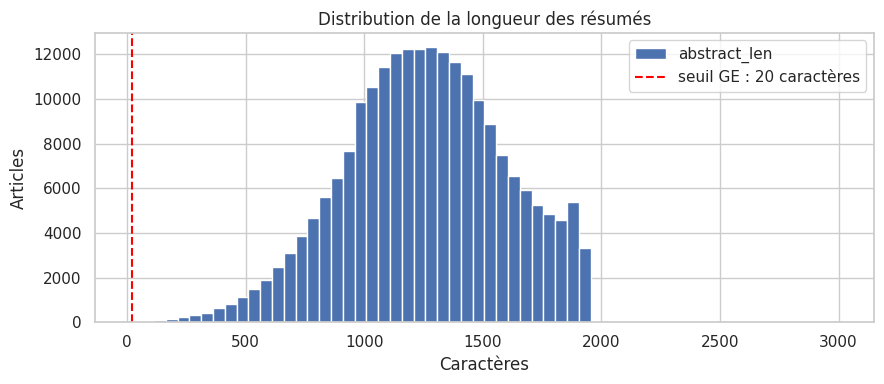

In [14]:
ax = arxiv["abstract_len"].clip(upper=3000).plot.hist(bins=60, figsize=(9, 4))
ax.axvline(20, color="red", ls="--", label="seuil GE : 20 caractères")
ax.set(title="Distribution de la longueur des résumés", xlabel="Caractères", ylabel="Articles"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "01_longueur_resumes.png", dpi=120); plt.show()

### 2.4 Signal Hacker News

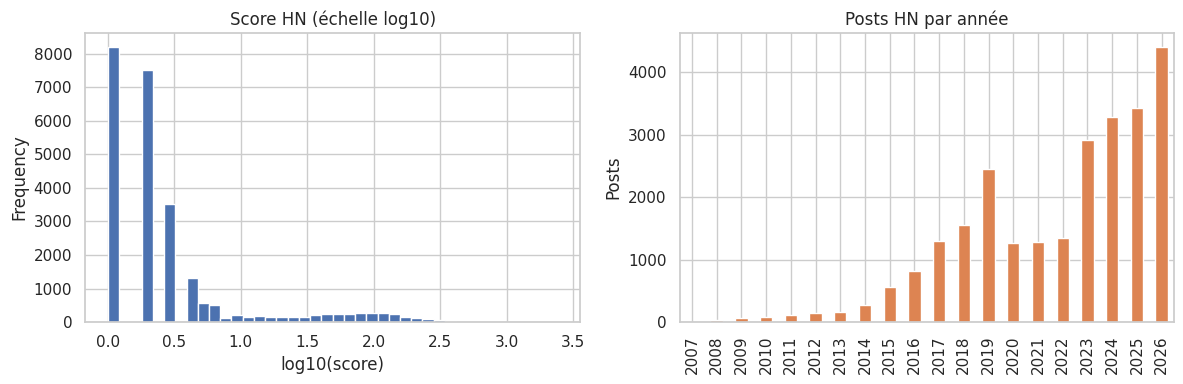

Médiane du score : 2 — 99e centile : 232 — max : 2,408
93.5% des posts HN pointent vers un article ArXiv


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hn["score"].clip(lower=1).pipe(np.log10).plot.hist(bins=40, ax=axes[0])
axes[0].set(title="Score HN (échelle log10)", xlabel="log10(score)")
hn.groupby("year").size().plot.bar(ax=axes[1], color=sns.color_palette()[1])
axes[1].set(title="Posts HN par année", xlabel="", ylabel="Posts")
plt.tight_layout(); plt.savefig(FIG / "01_hn.png", dpi=120); plt.show()

print(f"Médiane du score : {hn.score.median():.0f} — 99e centile : {hn.score.quantile(.99):.0f} — max : {hn.score.max():,}")
print(f"{hn.arxiv_id.notna().mean():.1%} des posts HN pointent vers un article ArXiv")

La distribution des scores HN est **très asymétrique** (quelques posts viraux, une majorité à quelques points) :
c'est ce qui justifie la **transformation logarithmique** (`log1p`) du signal HN dans le score d'impact.

### 2.5 Citations académiques

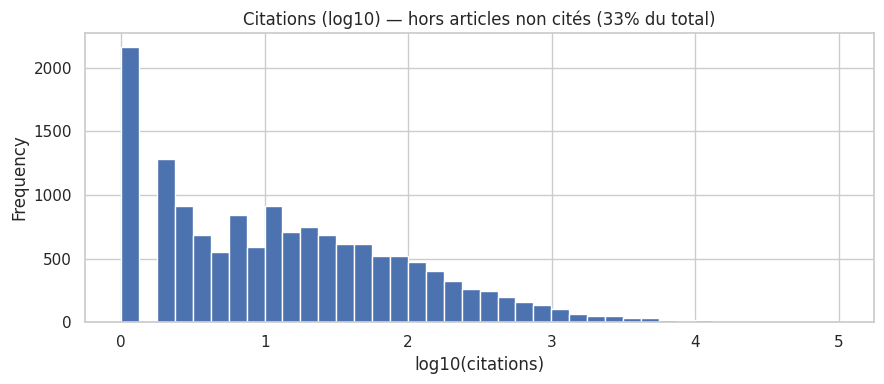

,count,mean,std,min,50%,90%,99%,max
cited_by_count,22472.0,123.6,1313.1,0.0,3.0,123.0,1883.2,99045.0


In [16]:
zero = cit["cited_by_count"].eq(0).mean()
fig, ax = plt.subplots(figsize=(9, 4))
cit.loc[cit.cited_by_count > 0, "cited_by_count"].pipe(np.log10).plot.hist(bins=40, ax=ax)
ax.set(title=f"Citations (log10) — hors articles non cités ({zero:.0%} du total)", xlabel="log10(citations)")
plt.tight_layout(); plt.savefig(FIG / "01_citations.png", dpi=120); plt.show()
cit["cited_by_count"].describe(percentiles=[.5, .9, .99]).round(1).to_frame().T

La majorité des articles du corpus sont **récents** (2024+) et n'ont pas encore eu le temps d'être cités.
Conséquence pour le score d'impact : un classement en **percentile par catégorie** reste discriminant, mais il suffit de
quelques citations pour atteindre les centiles élevés. Ce point est analysé dans le notebook 02.

## 3. Validation Great Expectations & procédure de nettoyage

Les suites sont définies dans `src/scipulse/quality/suites.py` et exécutées à chaque passage Silver
(`src/scipulse/quality/runner.py`). Les résultats sont publiés dans les **Data Docs**
(`great_expectations/gx/uncommitted/data_docs/local_site/index.html`) et envoyés au dashboard de monitoring Kibana.

On reproduit ici les règles avec pandas, **sur Bronze (avant) et sur Silver (après)**, pour montrer l'effet du nettoyage.

In [17]:
from scipulse.cleaning.identifiers import normalize_arxiv_id
ID_RE = r"^(\d{4}\.\d{4,5}|[a-z\-]+(\.[a-z]{2})?/\d{7})$"

bronze = pd.DataFrame({
    "arxiv_id": arxiv_raw["id"],
    "primary_category": arxiv_raw["categories"].str.split().str[0],
    "abstract": arxiv_raw["abstract"],
})
def arxiv_rules(df):
    return pd.Series({
        "arxiv_id non nul": df.arxiv_id.notna().mean(),
        "arxiv_id unique": 1 - df.arxiv_id.duplicated().mean(),
        "arxiv_id au format normalisé": df.arxiv_id.astype(str).str.match(ID_RE).mean(),
        "primary_category non nul": df.primary_category.notna().mean(),
        "résumé ≥ 20 caractères": (df.abstract.fillna("").str.strip().str.len() >= 20).mean(),
    }).mul(100).round(3)

pd.DataFrame({"Bronze (avant)": arxiv_rules(bronze), "Silver (après)": arxiv_rules(arxiv)})

,Bronze (avant),Silver (après)
arxiv_id non nul,100.000,100.0
arxiv_id unique,100.000,100.0
arxiv_id au format normalisé,100.000,100.0
primary_category non nul,100.000,100.0
résumé ≥ 20 caractères,99.998,100.0


### Historique des validations ArXiv Silver

| Passage | Résultat | Analyse | Décision |
|---|---|---|---|
| 1 | **5/6 (83 %)** | 1 ligne sur 218 851 en échec : l'article `1110.2832`, résumé « *Probably not.* » (13 caractères) | Article **légitime** (résumé humoristique) : on **garde la donnée** |
| 2 | **6/6 (100 %)** | Règle assouplie : `mostly=0.999` (tolère 0,1 % d'exceptions) | Le monitoring Kibana conserve la trace du passage à 83 % |

> Supprimer cette ligne aurait « réparé » l'indicateur au prix d'une perte d'information. Une règle de qualité doit
> **détecter les anomalies**, l'analyse humaine décide ensuite s'il s'agit d'une erreur ou d'une valeur légitime.

### Règles de nettoyage appliquées (Bronze → Silver)

| Source | Problème constaté | Traitement | Code |
|---|---|---|---|
| ArXiv | Identifiants avec version (`v2`), préfixe `arXiv:` | Normalisation `2301.12345v2 → 2301.12345` | `cleaning/identifiers.py` |
| ArXiv | Date de soumission dans `versions[0].created` (RFC 2822) | Parsing → `submitted_date` (UTC), `year` | `cleaning/arxiv.py` |
| ArXiv | Titres / résumés multi-lignes | Espaces normalisés, `strip()` | `cleaning/arxiv.py` |
| ArXiv | `categories` multi-valuée | Liste + `primary_category` + `category_group` | `cleaning/arxiv.py` |
| ArXiv | Doublons d'identifiant | `drop_duplicates(keep="last")` | `cleaning/arxiv.py` |
| HN | Deux schémas d'API | Harmonisation vers un schéma unique | `cleaning/hn.py` |
| HN | Doublons poll / backfill | Dédup. sur `hn_id`, score max conservé | `cleaning/hn.py` |
| HN | Items supprimés, `dead`, non-stories | Filtrés | `cleaning/hn.py` |
| HN | Id ArXiv absent | Extraction depuis l'URL (regex) | `cleaning/identifiers.py` |
| Citations | DOI ≠ DOI arXiv | Id ArXiv retrouvé via `locations` | `ingestion/citations.py` |
| Toutes | Timestamps pandas en nanosecondes | Écriture Parquet en microsecondes (lisible par Spark 3.5) | `common/parquet.py` |

Toutes les règles sont couvertes par des **tests unitaires** (`tests/`, 21 tests, `make test`).

## 4. Couverture des jointures entre sources

In [18]:
ids = set(arxiv.arxiv_id)
hn_with_id = hn[hn.arxiv_id.notna()]
cov = pd.Series({
    "posts HN avec un id ArXiv": len(hn_with_id),
    "… dont l'article est dans le corpus": int(hn_with_id.arxiv_id.isin(ids).sum()),
    "articles avec des données de citation": int(cit.arxiv_id.isin(ids).sum()),
    "articles avec ≥ 1 citation": int(cit[cit.cited_by_count > 0].arxiv_id.isin(ids).sum()),
})
cov.to_frame("valeur")

,valeur
posts HN avec un id ArXiv,23852
… dont l'article est dans le corpus,23838
articles avec des données de citation,22472
articles avec ≥ 1 citation,14973


### Évolution de la couverture HN × ArXiv

| Échantillon ArXiv | Couverture | Explication |
|---|---|---|
| 200 000 **premières** lignes du dump | **1,3 %** (306 / 23 842) | Le dump est trié chronologiquement : échantillon 2007–2009, alors que HN discute surtout d'articles récents |
| Articles 2024+ du périmètre seulement | **35,8 %** (8 528) | Ce que le périmètre récent capte « naturellement » |
| Périmètre `cs.*`/`stat.ML` 2024+ **+ tous les articles cités sur HN** | **≈ 100 %** (23 834) | Couverture **par construction** (choix de conception assumé) |

## 5. Synthèse

- Les trois sources présentent des problèmes de qualité **différents** (schémas hétérogènes, doublons, clés de jointure
  absentes ou trompeuses) : chacun a été identifié sur Bronze puis traité en Silver.
- Les validations Great Expectations passent à **100 %** sur les trois sources après nettoyage, et l'unique échec observé a
  été **analysé** plutôt que masqué.
- Deux **biais** sont à garder en tête pour la suite : le corpus est **très récent** (peu de citations) et la couverture
  OpenAlex est **partielle** (« 0 citation » peut signifier « pas de données »).